In [1]:
import json
import numpy as np
import pandas as pd

In [2]:
nodes = json.load(open("./data/vertices.json"))
labels = list(nodes.keys())
pts = np.array([nodes[l] for l in labels])

# distancia euclidiana entre todos os pares
D = np.sqrt(((pts[:, None, :] - pts[None, :, :]) ** 2).sum(axis=-1))
df = pd.DataFrame(D, index=labels, columns=labels).round(1)

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

img = plt.imread("./data/map.png")
pos = { label: tuple(coords) for label, coords in nodes.items() } 

[]

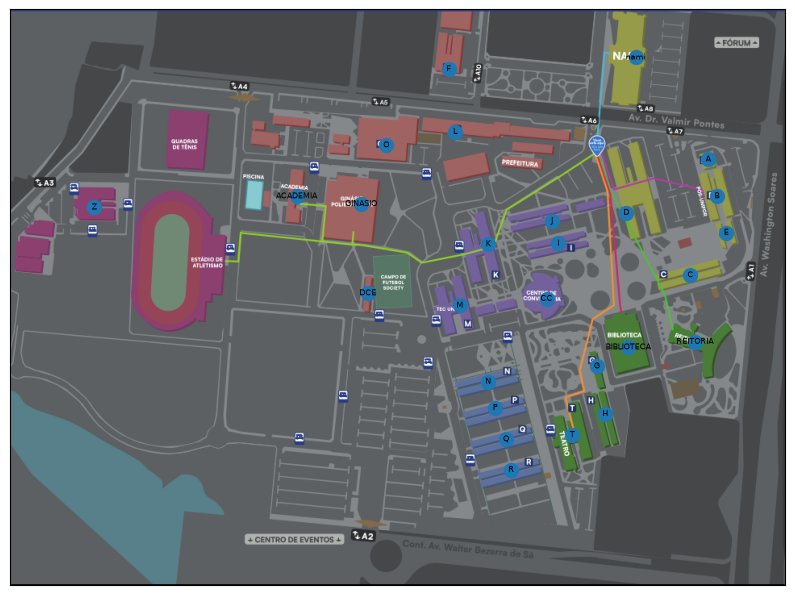

In [15]:
G = nx.Graph()
G.add_nodes_from(labels)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img)

nx.draw_networkx_nodes(G, pos, ax=ax, node_size=100)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=6)
nx.draw_networkx_edges(G, pos, ax=ax)

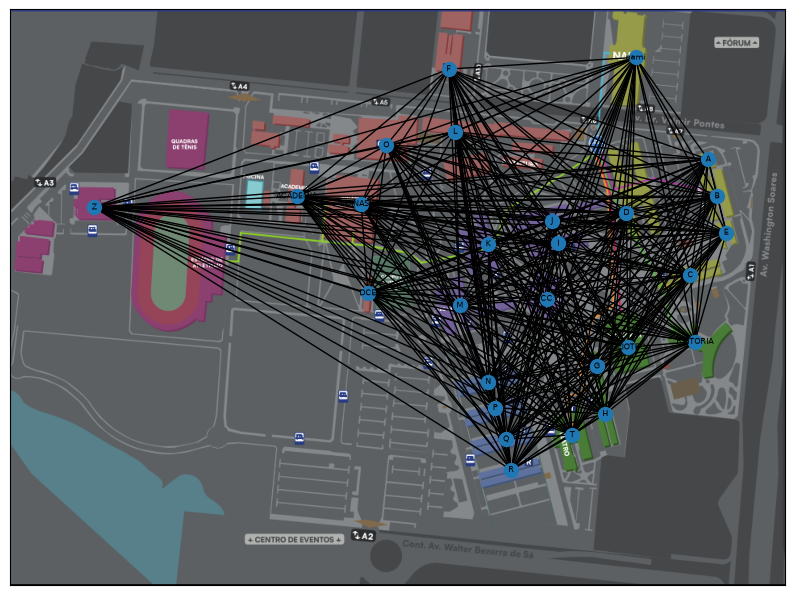

In [14]:
G_with_edges = nx.from_pandas_adjacency(df)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img)

nx.draw_networkx_nodes(G_with_edges, pos, ax=ax, node_size=100)
nx.draw_networkx_labels(G_with_edges, pos, ax=ax, font_size=6)
nx.draw_networkx_edges(G_with_edges, pos, ax=ax)

In [9]:
import math
from queue import PriorityQueue

def MSTPrim(graph: nx.Graph, s):
    newGraph = nx.Graph()      
    keys = {}                  
    predecessors = {}          

    for v in graph.nodes:
        keys[v] = math.inf
        predecessors[v] = None
    keys[s] = 0

    queue = PriorityQueue()
    queue.put((keys[s], s))  

    visited = set()         

    while not queue.empty():
        key, u = queue.get()
        if u in visited:      
            continue
        visited.add(u)

        if predecessors[u] is not None:
            newGraph.add_edge(predecessors[u], u, weight=key)

        for v in graph.neighbors(u):
            w = graph[u][v]['weight']
            if v not in visited and w < keys[v]:
                keys[v] = w
                predecessors[v] = u
                queue.put((keys[v], v))

    return newGraph

Custo total da MST: 2095.7


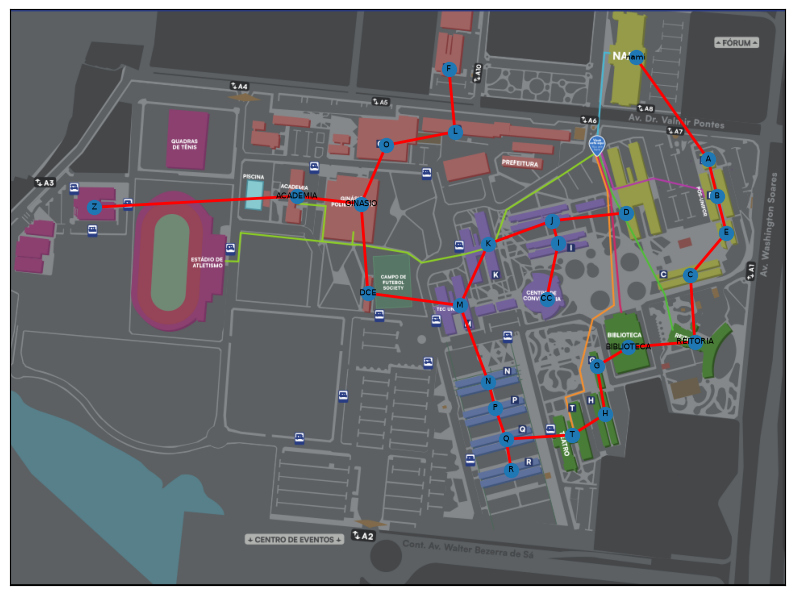

In [12]:
mst = MSTPrim(G_with_edges, "A")

total = sum(d['weight'] for _, _, d in mst.edges(data=True))
print(f"Custo total da MST: {total:.1f}")

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img)
nx.draw_networkx_nodes(G_with_edges, pos, ax=ax, node_size=100)
nx.draw_networkx_labels(G_with_edges, pos, ax=ax, font_size=6)
nx.draw_networkx_edges(mst, pos, ax=ax, edge_color='red', width=2)